# Test `neuromodes.morphometry` vs original Mode Based Morphometry

In this notebook we demonstrate use example data from the original repository to compare the present python implementation with the original MATLAB implementation. 

## Imports

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

In [2]:
import nibabel as nib
from brainspace.mesh.mesh_io import read_surface
from brainspace.vtk_interface.wrappers import BSPolyData

In [3]:
from neuromodes import EigenSolver
from neuromodes import mbm as mbm
from nsbutils.plotting import plot_surf

## Parameters/setup

In [4]:
# These are fixed for this demonstration (in order to match the original's mbm_demo_sim.m)
n_permutations = 10 # the original uses 10, but we can easily use 100 or maybe 1000
n_for_pval_recalculation = None # there is no tail interpolation in the original example (where n_permutations=10 and pThr=0.1)
n_modes = 150
seed = 2
n_subjects = 25 # subjects per group
statTest = 'ttest'
alternative = 'two-sided'
permutationMethod = 'shuffle_rows'

In [5]:
# Load cortical surface mesh
surfpath = './validation_data/fsLR_32k_midthickness-lh.vtk'
medmask = np.loadtxt('./validation_data/mask_S1200.L.midthickness_MSMAll.32k_fs_LR.txt').astype(bool)
solver = EigenSolver(surfpath, mask=medmask).solve(n_modes)

# Generate BSPolyData object for plotting
# known warning here from brainspace/vtk
bssurf: BSPolyData = read_surface(surfpath) # type: ignore

In [6]:
print(solver)

EigenSolver
-----------
Surface mesh: 29696 vertices (2796 others masked out), 59147 triangles
Mass matrix: consistent
Stiffness matrix: homogeneous
Eigenmodes and eigenvalues: 150 computed


## Generate data

First, we generate the known difference between the two groups:

In [7]:
data_a = np.empty((solver.n_verts, n_subjects))
data_b = np.empty((solver.n_verts, n_subjects))

for i in range(n_subjects):
    temp = nib.load(f"./validation_data/thickness/thick_50_0.2_0.6_1_{i+1}.func.gii")
    data_a[:, i] = temp.darrays[0].data[medmask]

for i in range(n_subjects): 
    temp = nib.load(f"./validation_data/thickness/thick_50_0.2_0.6_1_{i+1+n_subjects}.func.gii")
    data_b[:, i] = temp.darrays[0].data[medmask]


We can visualise the first few example maps:

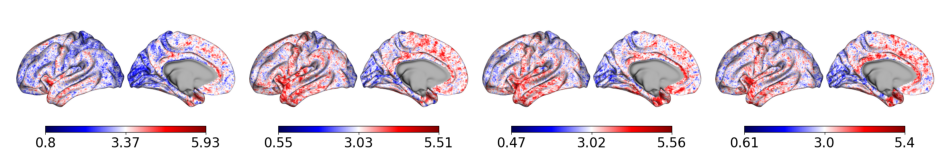

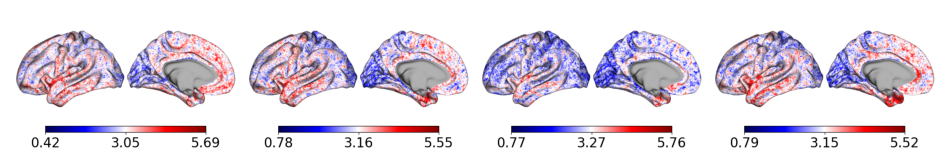

In [8]:
plot_surf(bssurf, solver.unmask_data(data_a[:,:4]), cmap='seismic', cbar=True)
plot_surf(bssurf, solver.unmask_data(data_b[:,:4]), cmap='seismic', cbar=True)

## Vertex-level t-test (surface based morphometry)

`neuromodes.morphometry` requires us to explicity construct design, response, and contrast matrices:

In [9]:
response = np.vstack((data_a.T, data_b.T))
design = np.kron(np.eye(2), np.ones((n_subjects, 1)))
contrast = np.array([[1, -1]])

We actually compute the vertex-level t-statistic using the function `mbm_generate_stat_maps`: 

In [10]:
t_observed = mbm.mbm_generate_stat_maps(design, response, contrast, statTest)
pattern_observed = t_observed / np.sqrt(n_subjects / 2)

We can visualise the theoretical and observed vertex-wise t-statistics: 

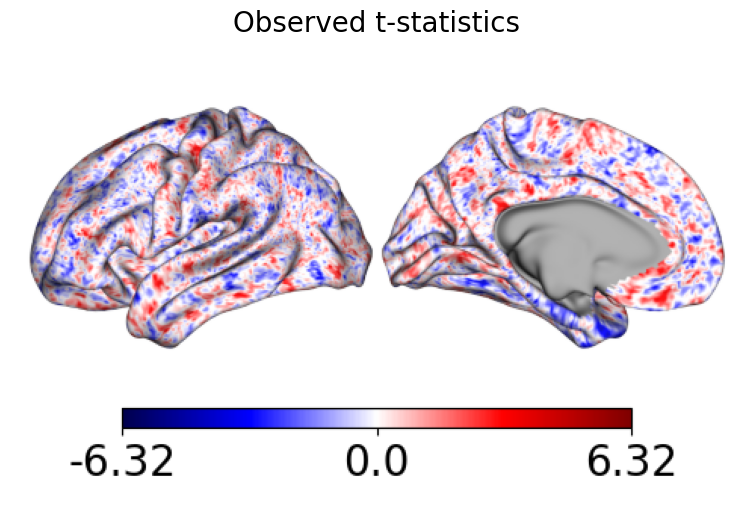

In [11]:
plot_surf(bssurf, solver.unmask_data(t_observed), labels=['Observed t-statistics'], 
          cmap='seismic', cbar=True, center=0, ax=plt.subplots(1, 1, figsize=(12, 6))[1])


## Generating non-parametric p-values by permutation testing

First, we generate the null t-statistic maps. This is done by shuffling the design matrix (equivalent to randomising the group allocation in this example) and then computing new t-statistics at each vertex for each permutation. We use the function `mbm_generate_stat_maps` for this: 

In [12]:
# This takes around n_permutations seconds
t_permuted = mbm.mbm_generate_stat_maps(design, response, contrast, statTest, 
                                     n_permutations=n_permutations, 
                                     permutationMethod=permutationMethod, 
                                     seed=seed)

We can then compute the p-value at each vertex. In the present example, we do this using the simplest approach of counting how many null t-statistics are above/below the observed statistic. This is done with the function `mbm_calc_p_vals`: 

In [13]:
p_uncorrected = mbm.mbm_calc_p_vals(t_observed, t_permuted, alternative, 
                                 n_for_pval_recalculation=n_for_pval_recalculation)
p_observed = stats.false_discovery_control(p_uncorrected, method='bh')

We can compare the different p-values: 

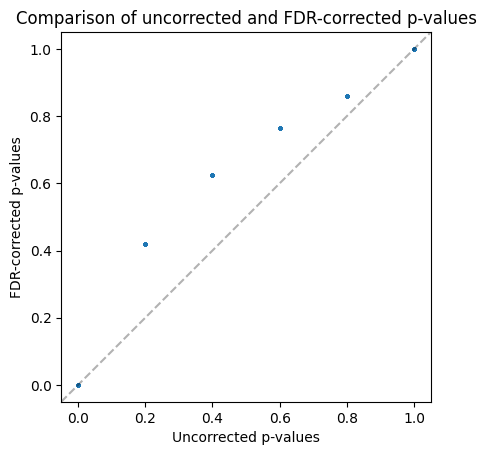

In [14]:
plt.scatter(p_uncorrected, p_observed, s=4)
plt.axline((0, 0), slope=1, color='black', linestyle='--', alpha=0.3)
plt.xlabel('Uncorrected p-values')
plt.ylabel('FDR-corrected p-values')
plt.axis('square')
plt.title('Comparison of uncorrected and FDR-corrected p-values')
plt.show()

We can visualise the p-value at each vertex. As expected, the p-value is high (~1) when the spatial pattern is near zero, and is low (~0) when the spatial pattern is far from zero. 

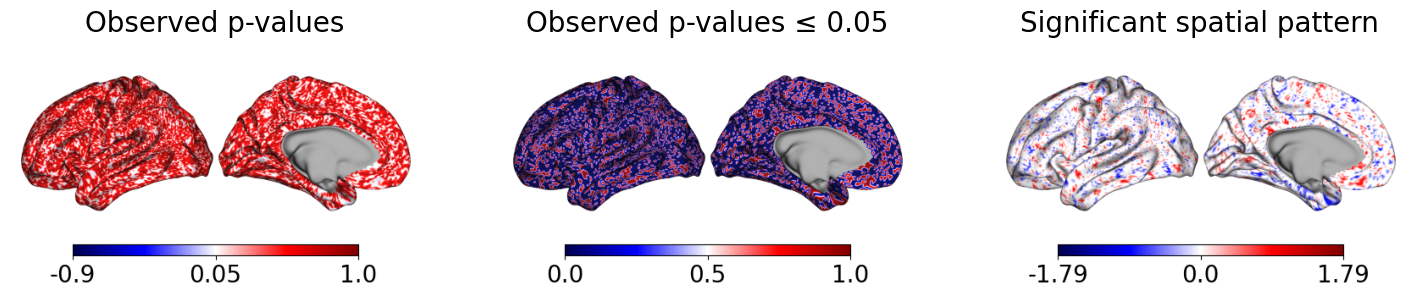

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(18, 8))
axs = axs.flatten()

plot_surf(bssurf, solver.unmask_data(p_observed), labels=['Observed p-values'],
          cmap='seismic', center=0.05, cbar=True, ax=axs[0])

plot_surf(bssurf, solver.unmask_data(p_observed<=0.05), labels=['Observed p-values ≤ 0.05'],
          cmap='seismic', color_range=(0.00, 1.00), cbar=True, ax=axs[1])

plot_surf(bssurf, solver.unmask_data((p_observed<0.05) * pattern_observed), labels=['Significant spatial pattern'], 
          cmap='seismic', center=0, cbar=True, ax=axs[2])

## Mode-level statistics (Mode Based Morphometry)

We can do a similar analysis but at the mode level rather than the vertex level. 

First, find the empirical loadings: 

In [16]:
beta_a = solver.decompose(data_a)
beta_b = solver.decompose(data_b)
beta_t = solver.decompose(t_observed)
response_mode = np.vstack((beta_a.T, beta_b.T))

Then find the empirical t-stat for each mode: 

In [17]:
t_mode = mbm.mbm_generate_stat_maps(design, response_mode, contrast, statTest)
pattern_mode = t_mode / np.sqrt(n_subjects / 2)

The null t-stats for each mode: 

In [18]:
t_mode_nulls = mbm.mbm_generate_stat_maps(design, response_mode, contrast, statTest, 
                                           n_permutations=n_permutations, 
                                           permutationMethod=permutationMethod, 
                                           seed=seed)

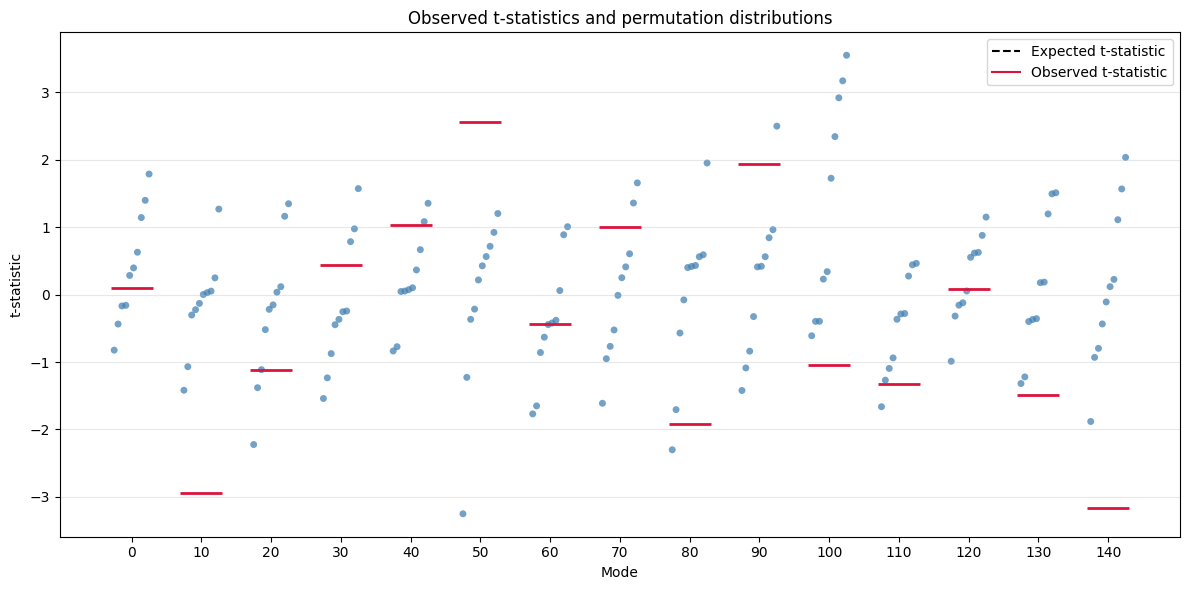

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))

# Swarm-like horizontal offsets for permutation values
offsets = np.linspace(-0.25, 0.25, n_permutations)

modes_to_plot = np.arange(0, n_modes, 10)
for i, mode in enumerate(modes_to_plot):
    ax.scatter(
        i + offsets,
        np.sort(t_mode_nulls[mode, :]),
        color='steelblue',
        alpha=0.75,
        s=25,
        edgecolor='none'
    )

    # Corresponding observed t-statistic
    ax.hlines(
        t_mode[mode],
        i - 0.3,
        i + 0.3,
        color='crimson',
        linewidth=2
    )

ax.set_xticks(np.arange(len(modes_to_plot)))
ax.set_xticklabels(modes_to_plot)

ax.set_xlabel('Mode')
ax.set_ylabel('t-statistic')
ax.set_title('Observed t-statistics and permutation distributions')
ax.legend(
    handles=[
        plt.Line2D([], [], color='black', linestyle='--',
                   label='Expected t-statistic'),
        plt.Line2D([], [], color='crimson',
                   label='Observed t-statistic')
    ]
)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

And the p-values: 

In [20]:
p_mode_uncorrected = mbm.mbm_calc_p_vals(t_mode, t_mode_nulls, alternative, 
                             n_for_pval_recalculation=n_for_pval_recalculation)
p_mode = stats.false_discovery_control(p_mode_uncorrected, method='bh')

beta_sig = p_mode <= 0.05
beta_order = np.argsort(np.abs(beta_t)*beta_sig)[::-1]

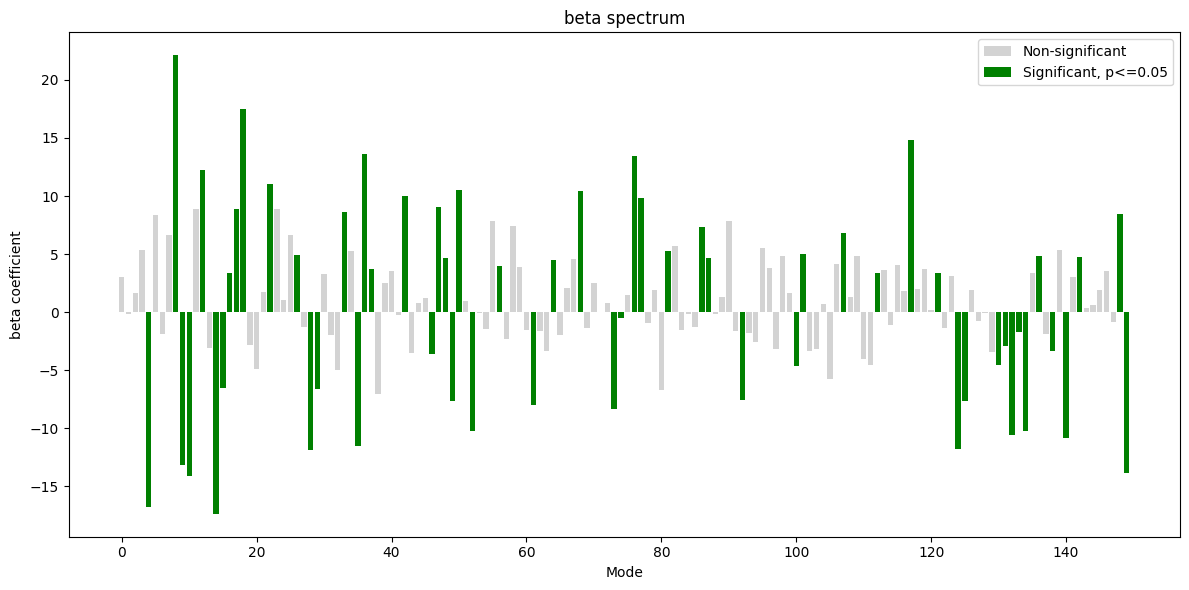

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(np.arange(n_modes)[~beta_sig], beta_t[~beta_sig], 
       color='lightgray', label='Non-significant')
ax.bar(np.arange(n_modes)[beta_sig], beta_t[beta_sig], 
       color='green', label='Significant, p<=0.05')

ax.set_xlabel('Mode')
ax.set_ylabel('beta coefficient')
ax.set_title('beta spectrum')
ax.legend()
plt.tight_layout()
plt.show()

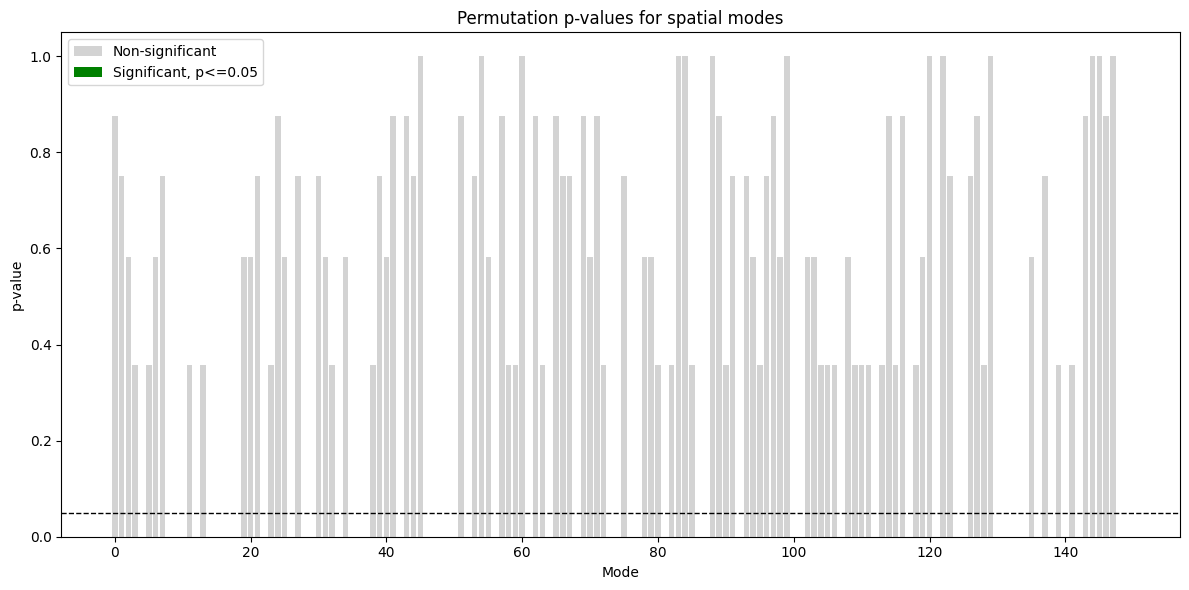

In [22]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(np.arange(n_modes)[~beta_sig], p_mode[~beta_sig], 
       color='lightgray', label='Non-significant')
ax.bar(np.arange(n_modes)[beta_sig], p_mode[beta_sig], 
       color='green', label='Significant, p<=0.05')
ax.axhline(0.05, color='black', linestyle='--', linewidth=1)

ax.set_xlabel('Mode')
ax.set_ylabel('p-value')
ax.set_title('Permutation p-values for spatial modes')
ax.legend()
plt.tight_layout()
plt.show()

In [23]:
# Have to rescale modes by their mass-weighted L2 norm to ensure that units/magnitudes are correct
# This arises when the data is projected onto the modes using the mass matrix
_modes_rescaled = solver.emodes * np.linalg.norm(solver.mass @ solver.emodes, axis=0)
mode_pattern_all = (_modes_rescaled @ (pattern_mode)[:, np.newaxis]).flatten()
mode_pattern_sig = (_modes_rescaled @ (pattern_mode * beta_sig)[:, np.newaxis]).flatten()

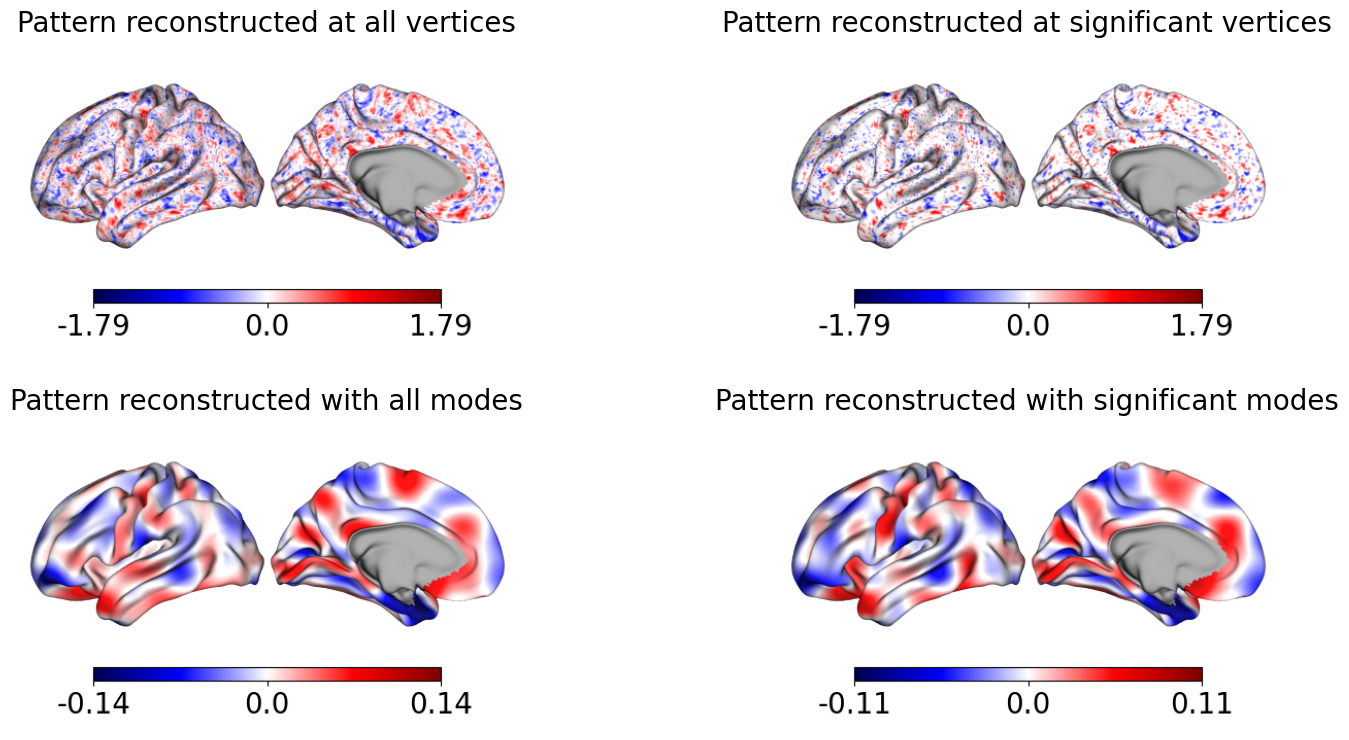

In [24]:
fig, axs = plt.subplots(2, 2, figsize=(18, 9))
axs = axs.flatten()

plot_surf(bssurf, solver.unmask_data(pattern_observed), labels=['Pattern reconstructed at all vertices'],
          cmap='seismic', center=0, cbar=True, ax=axs[0])

plot_surf(bssurf, solver.unmask_data((p_observed<=0.05) * pattern_observed), labels=['Pattern reconstructed at significant vertices'], 
          cmap='seismic', center=0, cbar=True, ax=axs[1])

plot_surf(bssurf, solver.unmask_data(mode_pattern_all), labels=['Pattern reconstructed with all modes'],
          cmap='seismic', center=0, cbar=True, ax=axs[2])

plot_surf(bssurf, solver.unmask_data(mode_pattern_sig), labels=['Pattern reconstructed with significant modes'],
          cmap='seismic', center=0, cbar=True, ax=axs[3])


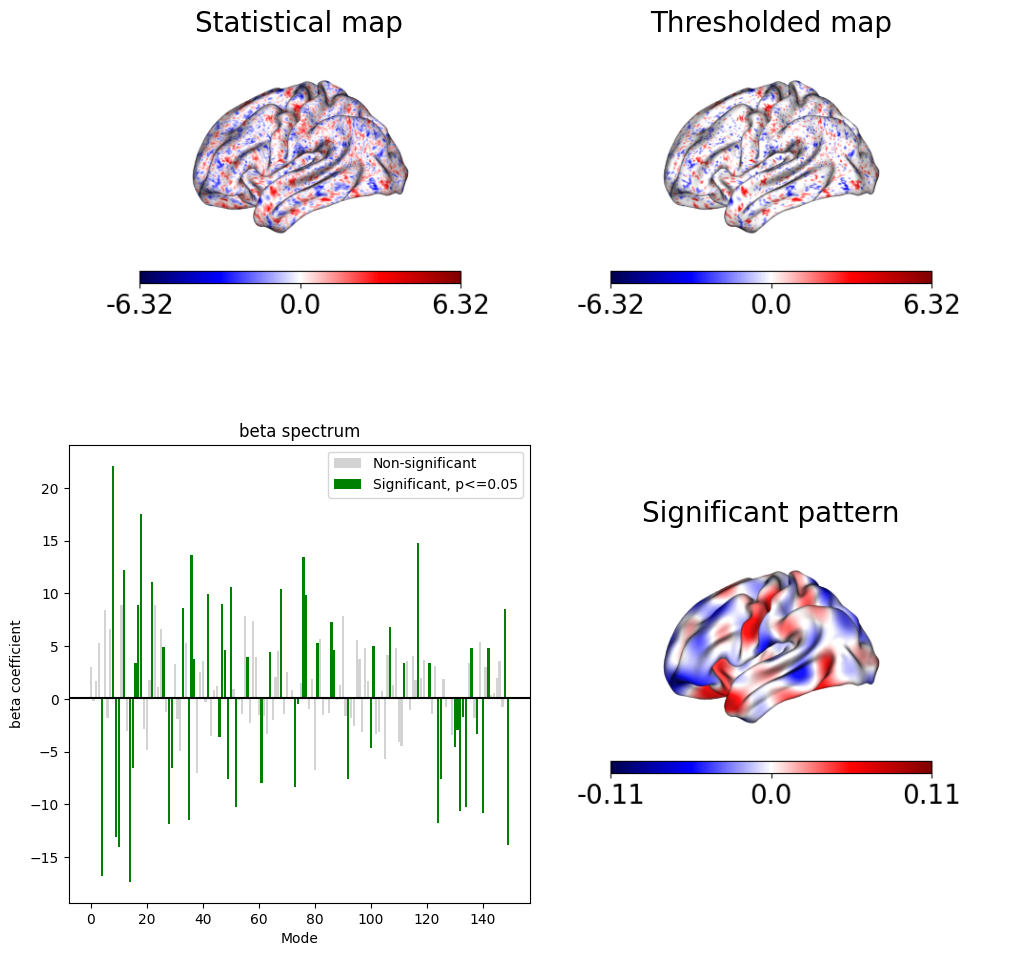

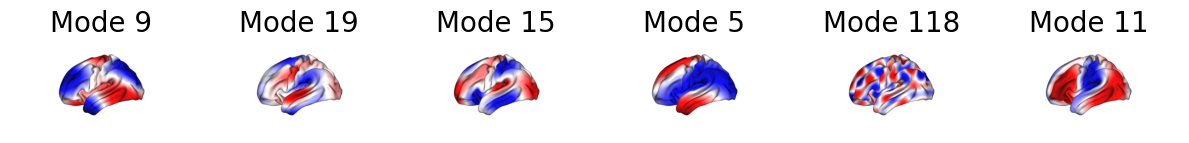

In [25]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10), layout="constrained")
axs = axs.flatten()

ax = axs[0]
plot_surf(bssurf, solver.unmask_data(t_observed), labels=['Statistical map'],
          cmap='seismic', center=0, cbar=True, ax=ax, views=['lateral'])

ax = axs[1]
plot_surf(bssurf, solver.unmask_data((p_observed<=0)*t_observed), labels=['Thresholded map'],
          cmap='seismic', center=0, cbar=True, ax=ax, views=['lateral'])

ax = axs[2]
ax.bar(np.arange(n_modes)[~beta_sig], beta_t[~beta_sig], 
       color='lightgray', label='Non-significant')
ax.bar(np.arange(n_modes)[beta_sig], beta_t[beta_sig], 
       color='green', label='Significant, p<=0.05')
ax.axhline(0.05, color='black')

ax.set_xlabel('Mode')
ax.set_ylabel('beta coefficient')
ax.set_title('beta spectrum')
ax.legend()

ax = axs[3]
plot_surf(bssurf, solver.unmask_data(mode_pattern_sig), labels=['Significant pattern'], 
          cmap='seismic', center=0, cbar=True, ax=ax, views=['lateral'])

fig, axs = plt.subplots(1, 6, figsize=(12, 6), layout="tight")
plot_surf(bssurf, solver.unmask_data(solver.emodes[:, beta_order[:6]]), 
          labels=[f'Mode {i+1}' for i in beta_order[:6]], ax=list(axs.flatten()), 
          cmap='seismic', center=0, cbar=False, views=['lateral'])
plt.show()


> ⚠️ **Check**: The python figure (above) and the MATLAB figure (below) should be very similar (there may be some slight differences as the permutations are not the same between the languages).

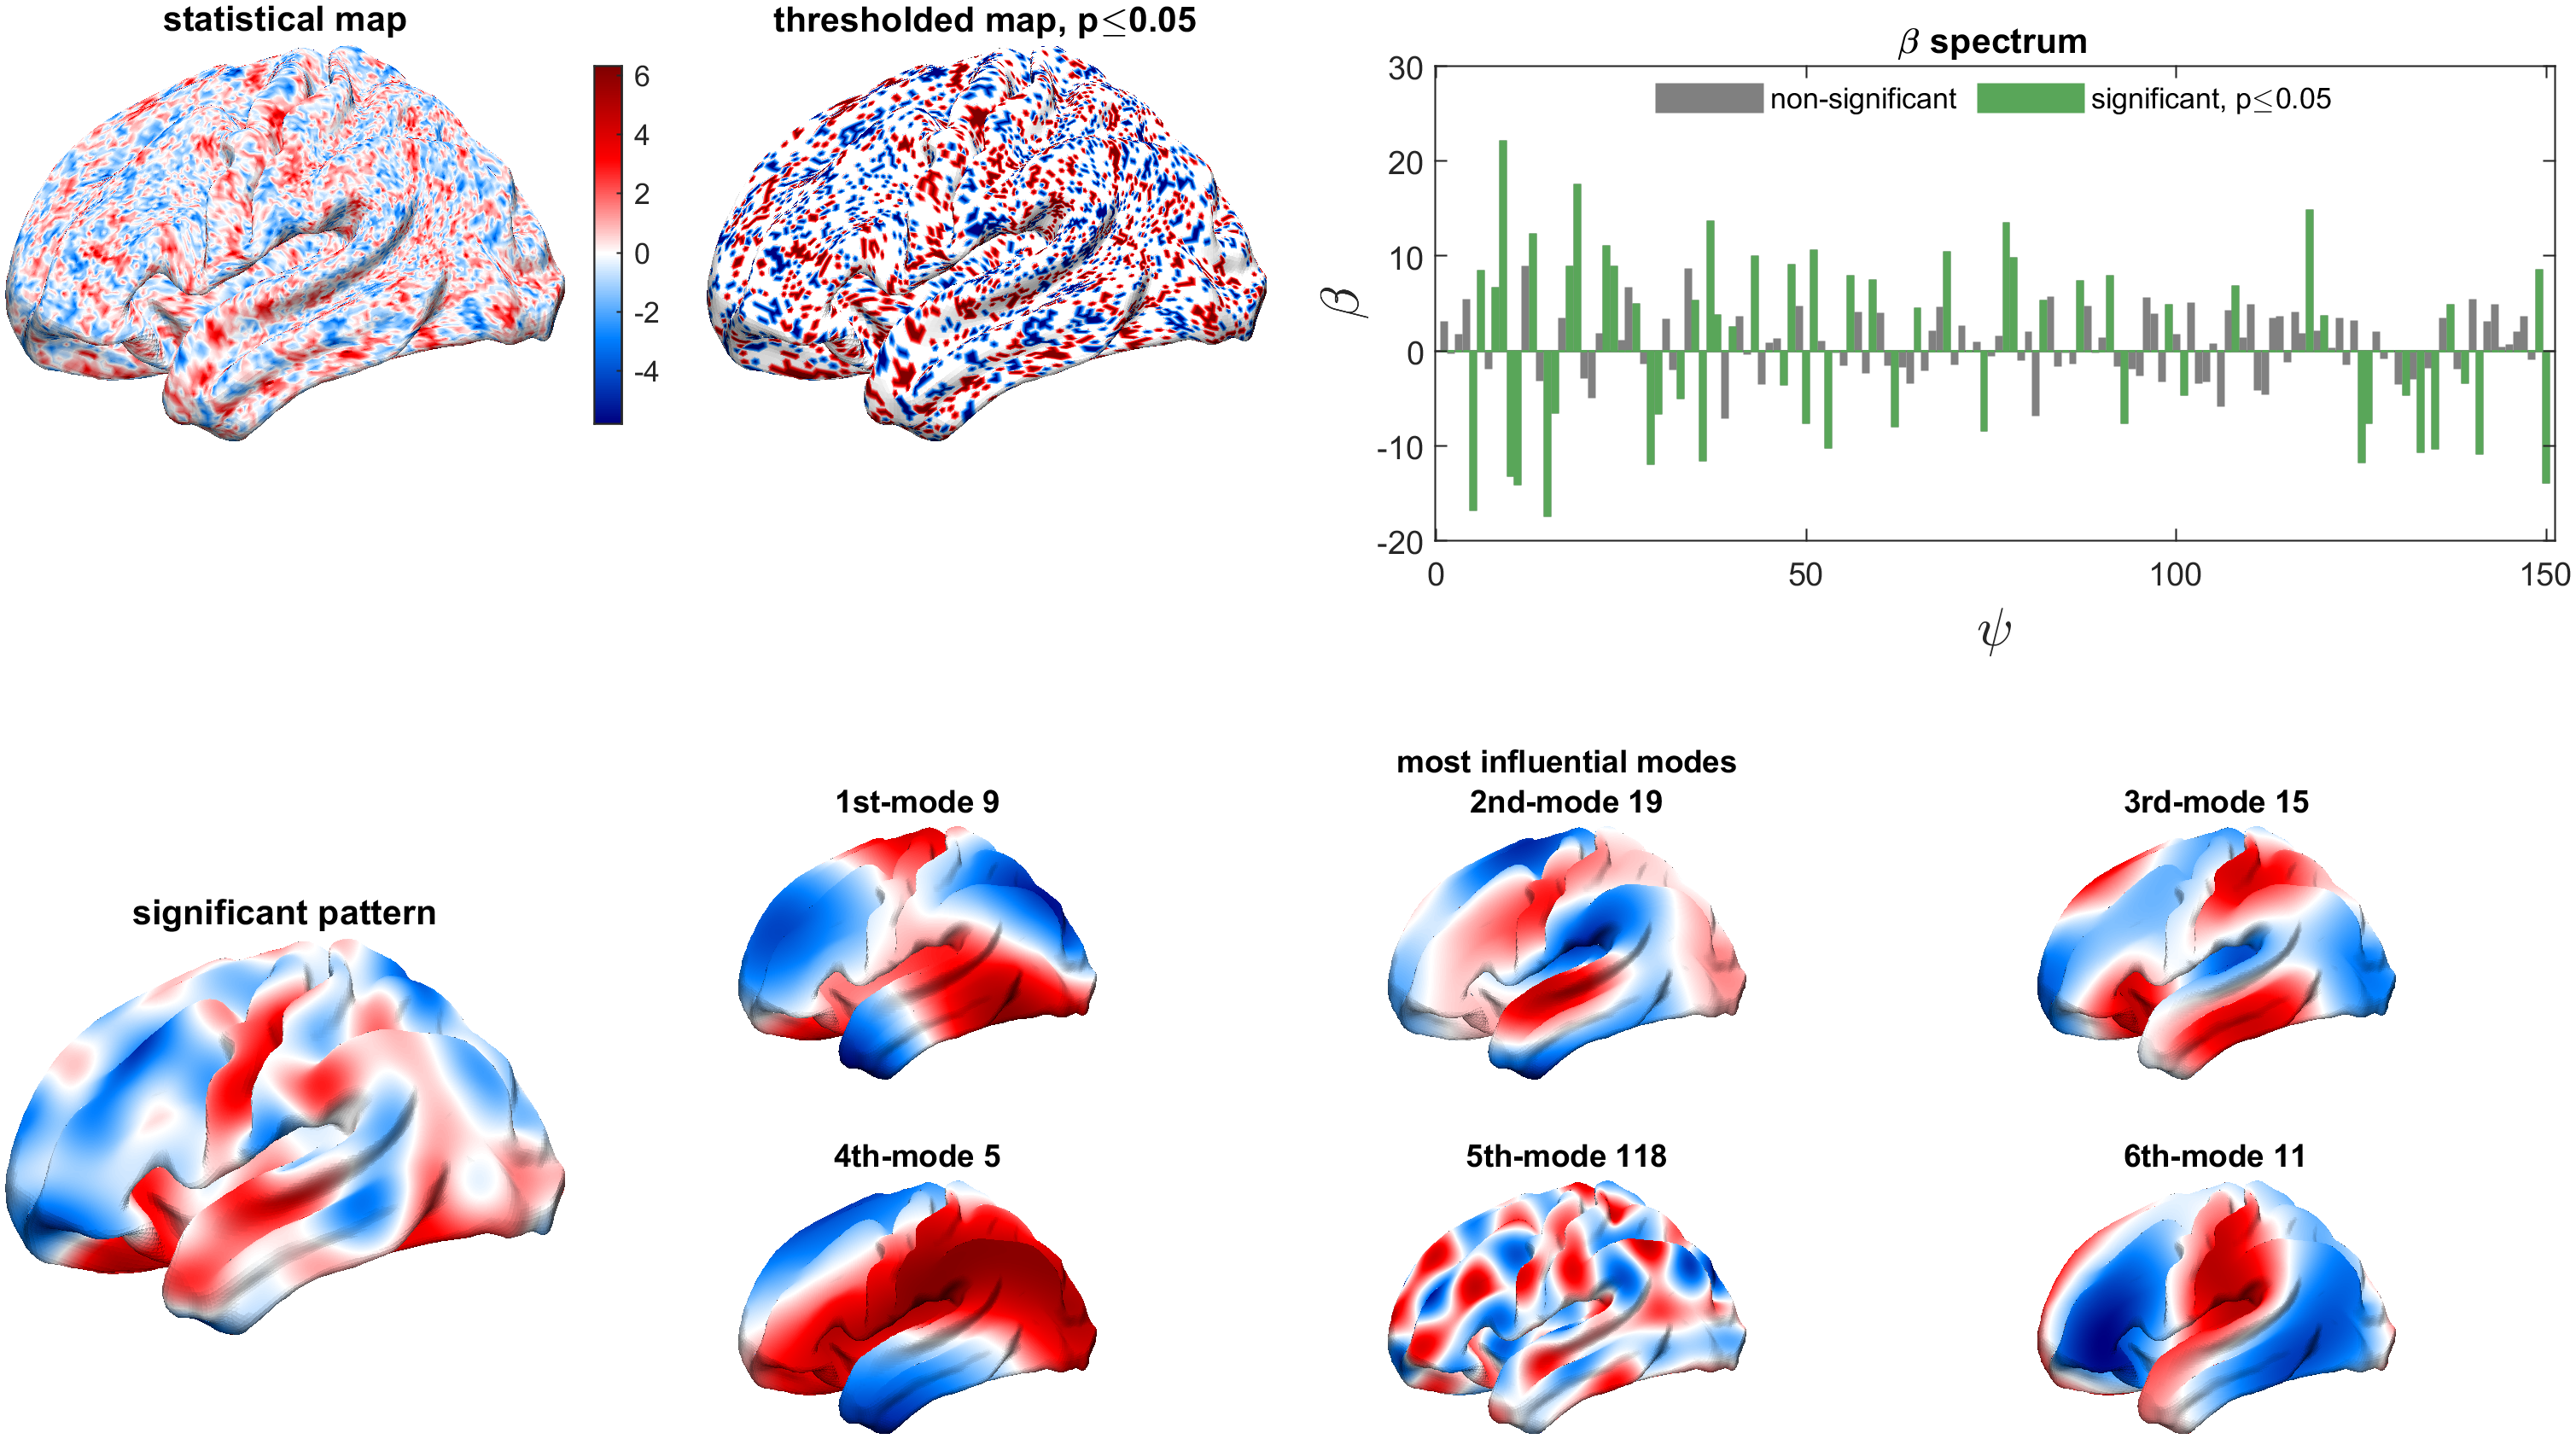